In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlaylistTrack.csv")
track = pd.read_csv("Track.csv")


# Usamos solo invoice, pero preparamos la fecha
df_ventas = invoice.copy()
df_ventas['InvoiceDate'] = pd.to_datetime(df_ventas['InvoiceDate'])
df_ventas['Mes_Año'] = df_ventas['InvoiceDate'].dt.to_period('M')

# Agrupar las ventas totales por mes
ventas_mensuales = df_ventas.groupby('Mes_Año')['Total'].sum()
display(ventas_mensuales.head(2))
# Convertir el índice (period) a string para que matplotlib lo grafique sin problemas
ventas_mensuales.index = ventas_mensuales.index.astype(str)
display(ventas_mensuales.head(2))

# Cruzar Tracks con Media Types para tener el nombre del formato
df_pistas_media = pd.merge(track, media, on="MediaTypeId", suffixes=('_Track', '_Media'))

# Convertir milisegundos a minutos y bytes a megabytes
df_pistas_media['Minutos'] = df_pistas_media['Milliseconds'] / 60000
df_pistas_media['Megabytes'] = df_pistas_media['Bytes'] / (1024 * 1024)

# Filtrar valores atípicos extremos para una mejor visualización
df_scatter = df_pistas_media[df_pistas_media['Minutos'] < 20]
df_scatter.head()


# Cruzar líneas de factura con canciones y luego con géneros
df_inv_trk = pd.merge(invoice_line, track, on="TrackId")
df_ventas_generos = pd.merge(df_inv_trk, genre, on="GenreId", suffixes=('_Track', '_Genre'))

# Sumar las ventas (Quantity * UnitPrice) por género
df_ventas_generos['Monto'] = df_ventas_generos['UnitPrice_x'] * df_ventas_generos['Quantity']
ingresos_por_genero = df_ventas_generos.groupby('Name_Genre')['Monto'].sum().sort_values(ascending=False)

# Tomar el top 5
top_5_generos = ingresos_por_genero.head(5)
top_5_generos

#storytelling of barchers leerlo (estrategia de ventas) 

Mes_Año
2021-01    35.64
2021-02    37.62
Freq: M, Name: Total, dtype: float64

Mes_Año
2021-01    35.64
2021-02    37.62
Name: Total, dtype: float64

Name_Genre
Rock                  826.65
Latin                 382.14
Metal                 261.36
Alternative & Punk    241.56
TV Shows               93.53
Name: Monto, dtype: float64

# Ejercicios


### Con el Dataframe `customer`, haz un `countplot` horizontal del número de clientes por país, ordenado de mayor a menor 

Index(['USA', 'Canada', 'France', 'Brazil', 'Germany'], dtype='str', name='Country')


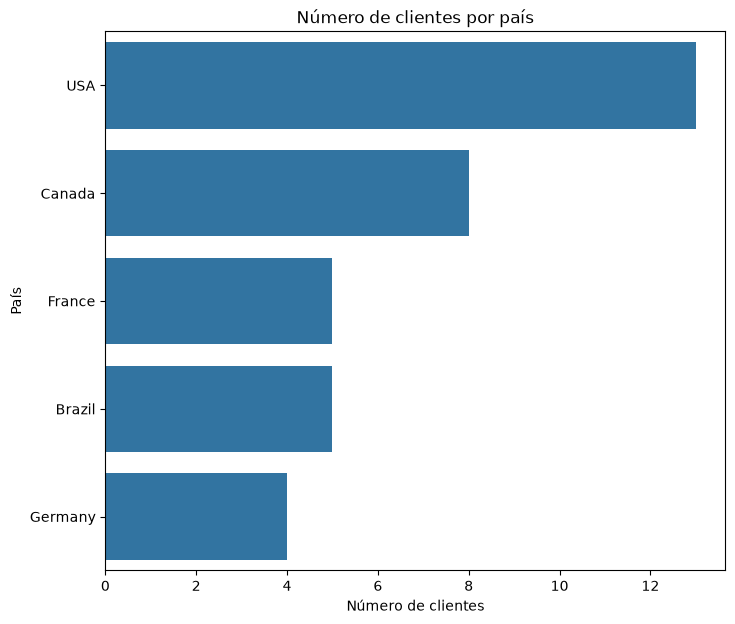

In [5]:
clientes_por_pais = customer.groupby("Country")["CustomerId"].count().sort_values(ascending=False).head(5).index
print(clientes_por_pais)



plt.figure(figsize=(8, 7))
sns.countplot(data=customer, y="Country", order=clientes_por_pais) 
plt.title("Número de clientes por país")
plt.xlabel("Número de clientes")
plt.ylabel("País")
plt.show()

### 2. Haz un `boxplot` del `Total` de las facturas por país, solo para los 5 países con más ingresos.
### ¿Algún país tiene facturas atípicamente grandes?

BillingCountry
USA        523.06
Canada     303.96
France     195.10
Brazil     190.10
Germany    156.48
Name: Total, dtype: float64


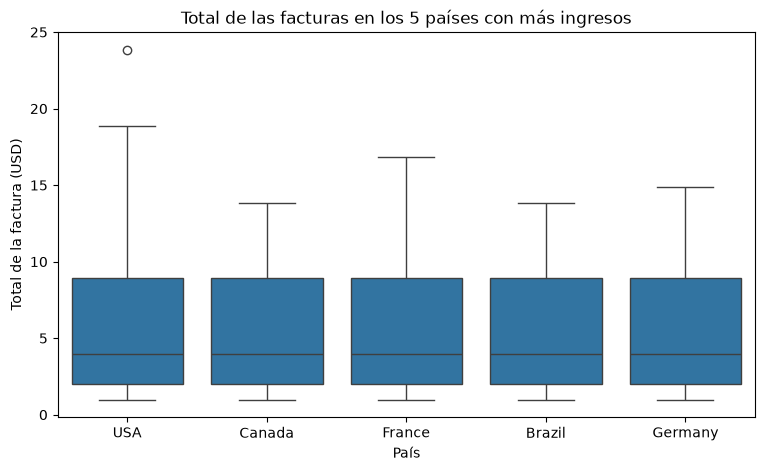

,InvoiceId,BillingCountry,Total
298,299,USA,23.86
200,201,USA,18.86
312,313,France,16.86
102,103,USA,15.86
192,193,Germany,14.91


In [ ]:
ingresos_por_pais = invoice.groupby("BillingCountry")["Total"].sum().sort_values(ascending=False)

top_5_paises_ingresos = ingresos_por_pais.head(5).index
print(ingresos_por_pais.head(5))


facturas_top_5_paises = invoice[invoice["BillingCountry"].isin(top_5_paises_ingresos)]

plt.figure(figsize=(9, 5))
sns.boxplot(data=facturas_top_5_paises, x="BillingCountry", y="Total", order=top_5_paises_ingresos)
plt.title("Total de las facturas en los 5 países con más ingresos")
plt.xlabel("País")
plt.ylabel("Total de la factura (USD)")
plt.show()


facturas_mas_grandes = facturas_top_5_paises.sort_values("Total", ascending=False).head(5)
facturas_mas_grandes[["InvoiceId", "BillingCountry", "Total"]]

#### Interpretación
Sí. **Estados Unidos** tiene una factura atípicamente grande de **23.86 USD**

### 3. Une `invoice` con `customer` (por `CustomerId`) y luego con `emloyee` (`SupportRepId` de `customer` corresponde a `EmployeeId`; usa `left_on/right_on`) y grafica con `barplot` los ingresos totales que atiende cada representante de soporte.

  NombreRepresentante   Total
0        Jane Peacock  833.04
1       Margaret Park  775.40
2       Steve Johnson  720.16


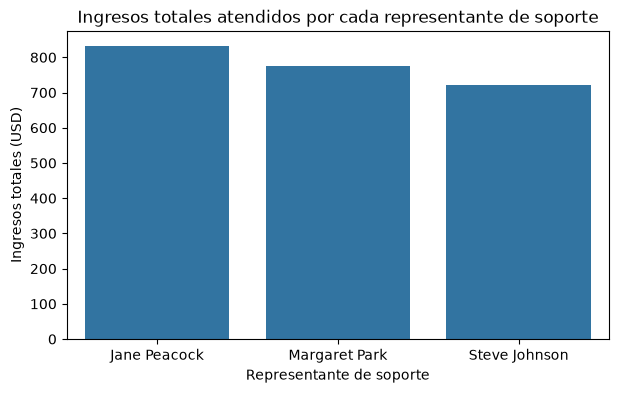

In [ ]:
union_facturas_con_clientes = invoice.merge(customer, on="CustomerId")

union_facturas_clientes_empleados = union_facturas_con_clientes.merge(
    employee,
    left_on="SupportRepId",
    right_on="EmployeeId",
    suffixes=("_Cliente", "_Empleado")
)


union_facturas_clientes_empleados["NombreRepresentante"] = (
    union_facturas_clientes_empleados["FirstName_Empleado"] + " "
    + union_facturas_clientes_empleados["LastName_Empleado"]
)


ingresos_por_representante = (
    union_facturas_clientes_empleados.groupby("NombreRepresentante")["Total"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
print(ingresos_por_representante)

plt.figure(figsize=(7, 4))
sns.barplot(data=ingresos_por_representante, x="NombreRepresentante", y="Total")
plt.title("Ingresos totales atendidos por cada representante de soporte")
plt.xlabel("Representante de soporte")
plt.ylabel("Ingresos totales (USD)")
plt.show()

#### Interpretación
**Jane Peacock** es la representante que atiende más ingresos (833.04 USD), seguida de **Margaret Park** (775.40) y **Steve Johnson** (720.16).

### 4. Crea una figura de 1×2 con `sharey=True`: a la izquierda el `violinplot` de duración para "Rock" y "Latin"; a la derecha el `stripplot` de los mismos datos.

              count      mean       std       min       25%       50%  \
Name_Genero                                                             
Latin         579.0  3.880988  1.120606  0.552483  3.157983  3.836517   
Rock         1297.0  4.731834  2.113259  0.017850  3.591833  4.327183   

                  75%        max  
Name_Genero                       
Latin        4.517000   9.050117  
Rock         5.326367  26.872150  


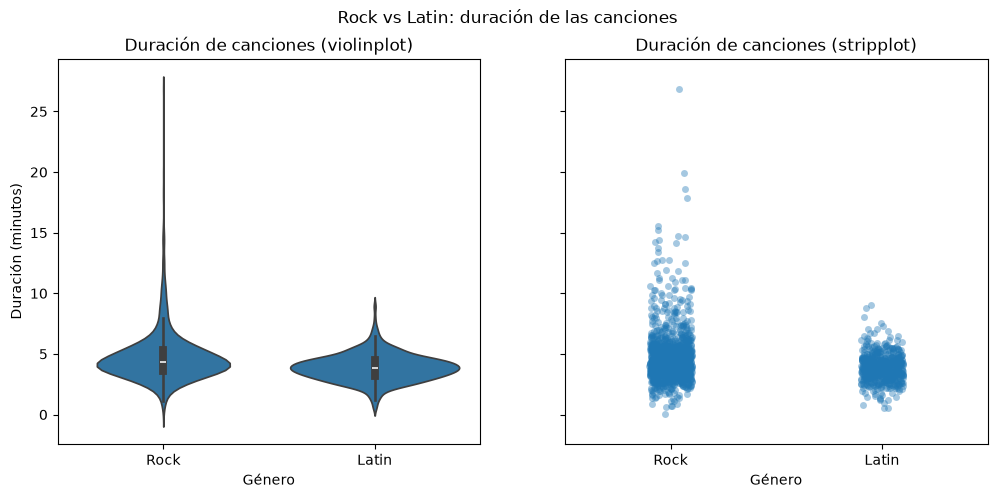

In [ ]:

canciones_con_genero = track.merge(genre, on="GenreId", suffixes=("_Cancion", "_Genero"))

# Duración de milisegundos a minutos
canciones_con_genero["Minutos"] = canciones_con_genero["Milliseconds"] / 60000


canciones_rock_y_latin = canciones_con_genero[canciones_con_genero["Name_Genero"].isin(["Rock", "Latin"])]
print(canciones_rock_y_latin.groupby("Name_Genero")["Minutos"].describe())

figura, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Izquierda: violinplot
sns.violinplot(data=canciones_rock_y_latin, x="Name_Genero", y="Minutos", ax=ejes[0])
ejes[0].set_title("Duración de canciones (violinplot)")
ejes[0].set_xlabel("Género")
ejes[0].set_ylabel("Duración (minutos)")

# Derecha: stripplot con los mismos datos
sns.stripplot(data=canciones_rock_y_latin, x="Name_Genero", y="Minutos", ax=ejes[1], alpha=0.4)
ejes[1].set_title("Duración de canciones (stripplot)")
ejes[1].set_xlabel("Género")

figura.suptitle("Rock vs Latin: duración de las canciones")
plt.show()

#### Interpretación
Las canciones de **Rock** duran en promedio más (4.7 min) que las de **Latin** (3.9 min) y su duración varía mucho más: hay canciones de Rock de más de 15 y hasta casi 27 minutos, mientras que ninguna canción Latin pasa de unos 9 minutos.


### 5. Construye un tablero de 2 × 3 con seis gráficas distintas de Chinook. Cada panel debe tener título, etiquetas de ejes en español y la figura un `suptitle`. Guárdalo como PNG a 200 dpi.

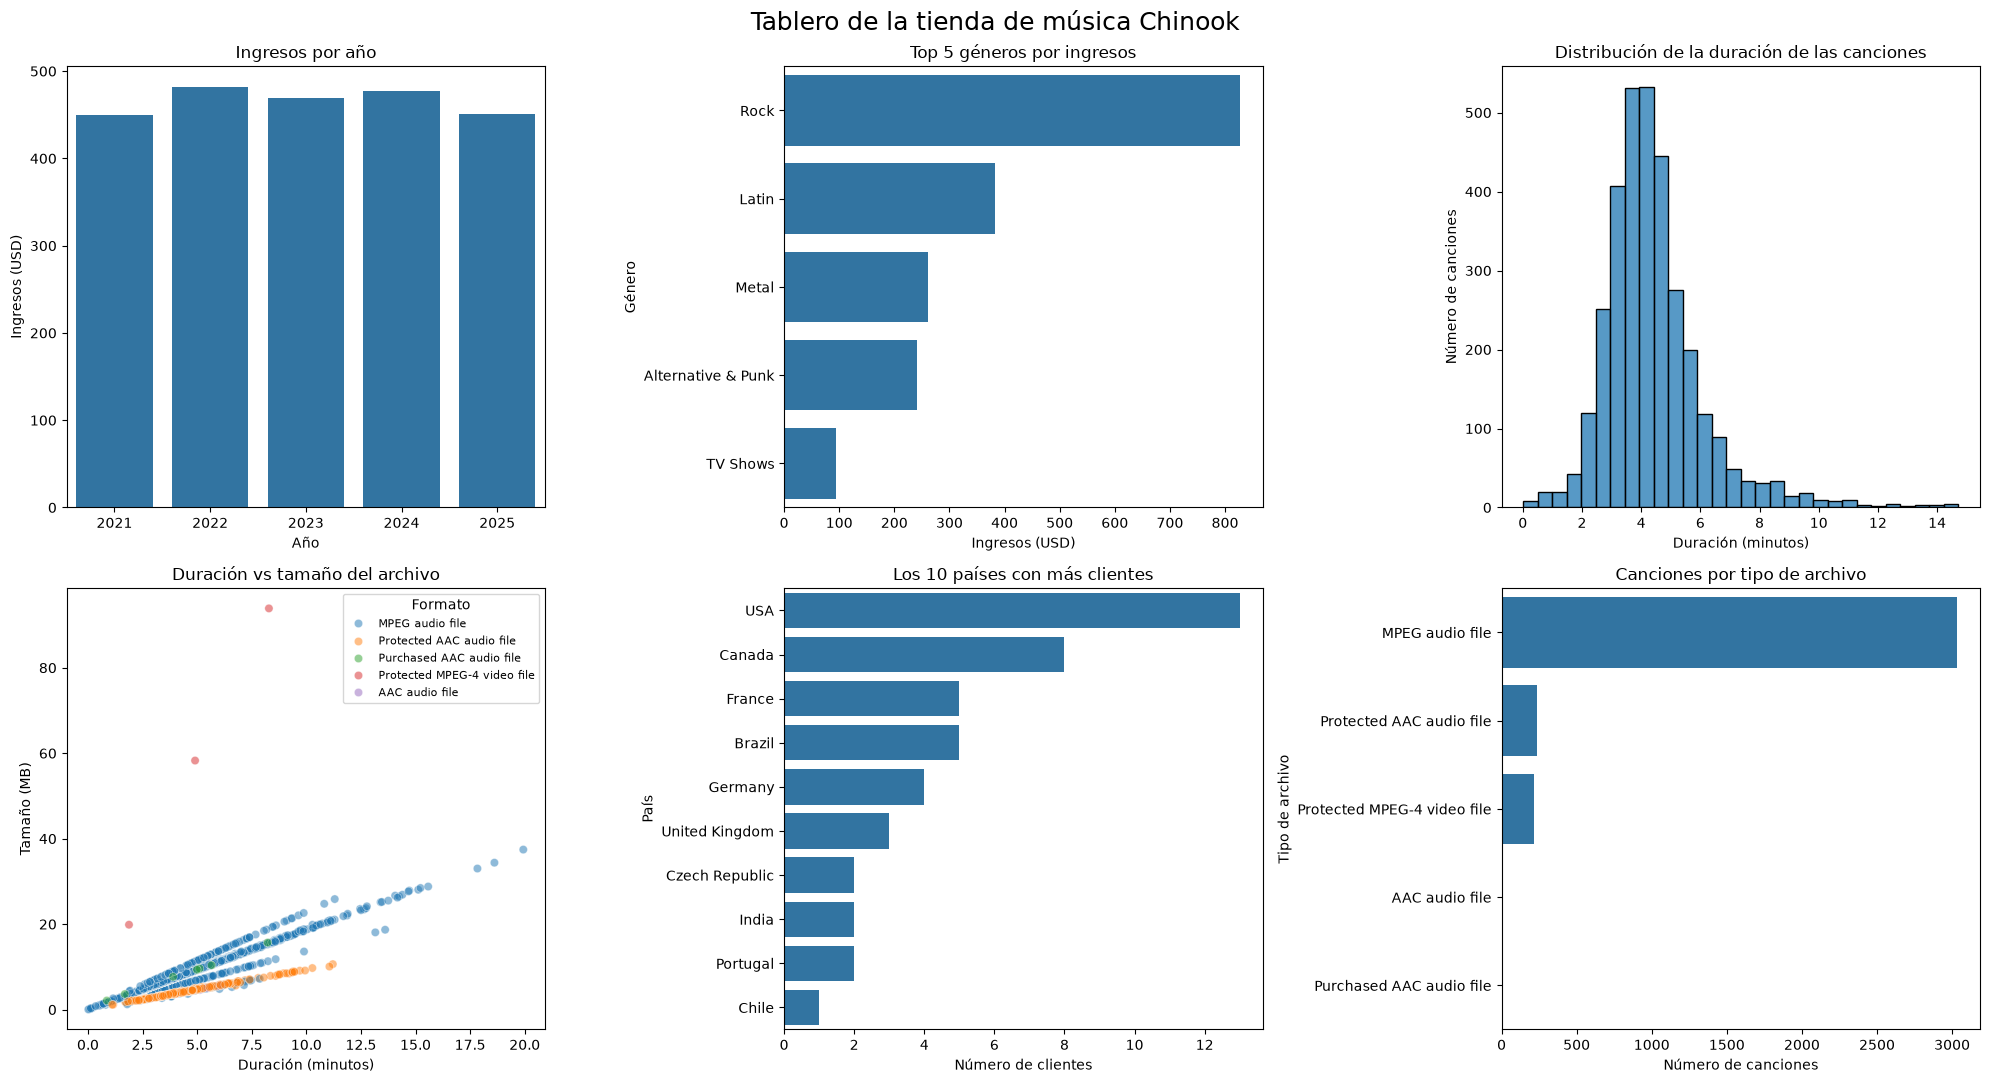

In [10]:


#Ingresos por año
facturas_con_fecha = invoice.copy()
facturas_con_fecha["InvoiceDate"] = pd.to_datetime(facturas_con_fecha["InvoiceDate"])
facturas_con_fecha["Año"] = facturas_con_fecha["InvoiceDate"].dt.year
ingresos_por_año = facturas_con_fecha.groupby("Año")["Total"].sum().reset_index()

#Top 5 géneros por ingresos
tabla_top_5_generos = top_5_generos.reset_index()

#Duración de las canciones 
canciones_menos_de_15_min = canciones_con_genero[canciones_con_genero["Minutos"] < 15]

#Minutos vs megabytes 

#Los 10 países con más clientes
clientes_por_pais = customer.groupby("Country")["CustomerId"].count().sort_values(ascending=False)
top_10_paises_clientes = clientes_por_pais.head(10).index

#Número de canciones por tipo de archivo
canciones_por_formato = df_pistas_media.groupby("Name_Media")["TrackId"].count().sort_values(ascending=False).reset_index()


figura, ejes = plt.subplots(2, 3, figsize=(20, 11))


sns.barplot(data=ingresos_por_año, x="Año", y="Total", ax=ejes[0, 0])
ejes[0, 0].set_title("Ingresos por año")
ejes[0, 0].set_xlabel("Año")
ejes[0, 0].set_ylabel("Ingresos (USD)")


sns.barplot(data=tabla_top_5_generos, x="Monto", y="Name_Genre", ax=ejes[0, 1])
ejes[0, 1].set_title("Top 5 géneros por ingresos")
ejes[0, 1].set_xlabel("Ingresos (USD)")
ejes[0, 1].set_ylabel("Género")


sns.histplot(data=canciones_menos_de_15_min, x="Minutos", bins=30, ax=ejes[0, 2])
ejes[0, 2].set_title("Distribución de la duración de las canciones")
ejes[0, 2].set_xlabel("Duración (minutos)")
ejes[0, 2].set_ylabel("Número de canciones")


sns.scatterplot(data=df_scatter, x="Minutos", y="Megabytes", hue="Name_Media", alpha=0.5, ax=ejes[1, 0])
ejes[1, 0].set_title("Duración vs tamaño del archivo")
ejes[1, 0].set_xlabel("Duración (minutos)")
ejes[1, 0].set_ylabel("Tamaño (MB)")
ejes[1, 0].legend(title="Formato", fontsize=8)


sns.countplot(data=customer, y="Country", order=top_10_paises_clientes, ax=ejes[1, 1])
ejes[1, 1].set_title("Los 10 países con más clientes")
ejes[1, 1].set_xlabel("Número de clientes")
ejes[1, 1].set_ylabel("País")


sns.barplot(data=canciones_por_formato, x="TrackId", y="Name_Media", ax=ejes[1, 2])
ejes[1, 2].set_title("Canciones por tipo de archivo")
ejes[1, 2].set_xlabel("Número de canciones")
ejes[1, 2].set_ylabel("Tipo de archivo")

figura.suptitle("Tablero de la tienda de música Chinook", fontsize=18)
plt.tight_layout()


plt.savefig("tablero_chinook.png", dpi=200)
plt.show()

### 6. Reproduce el `heatmap` de país × año, pero con el número de facturas en lugar del ingreso (`aggfunc="count"`). ¿Cambia la historia?

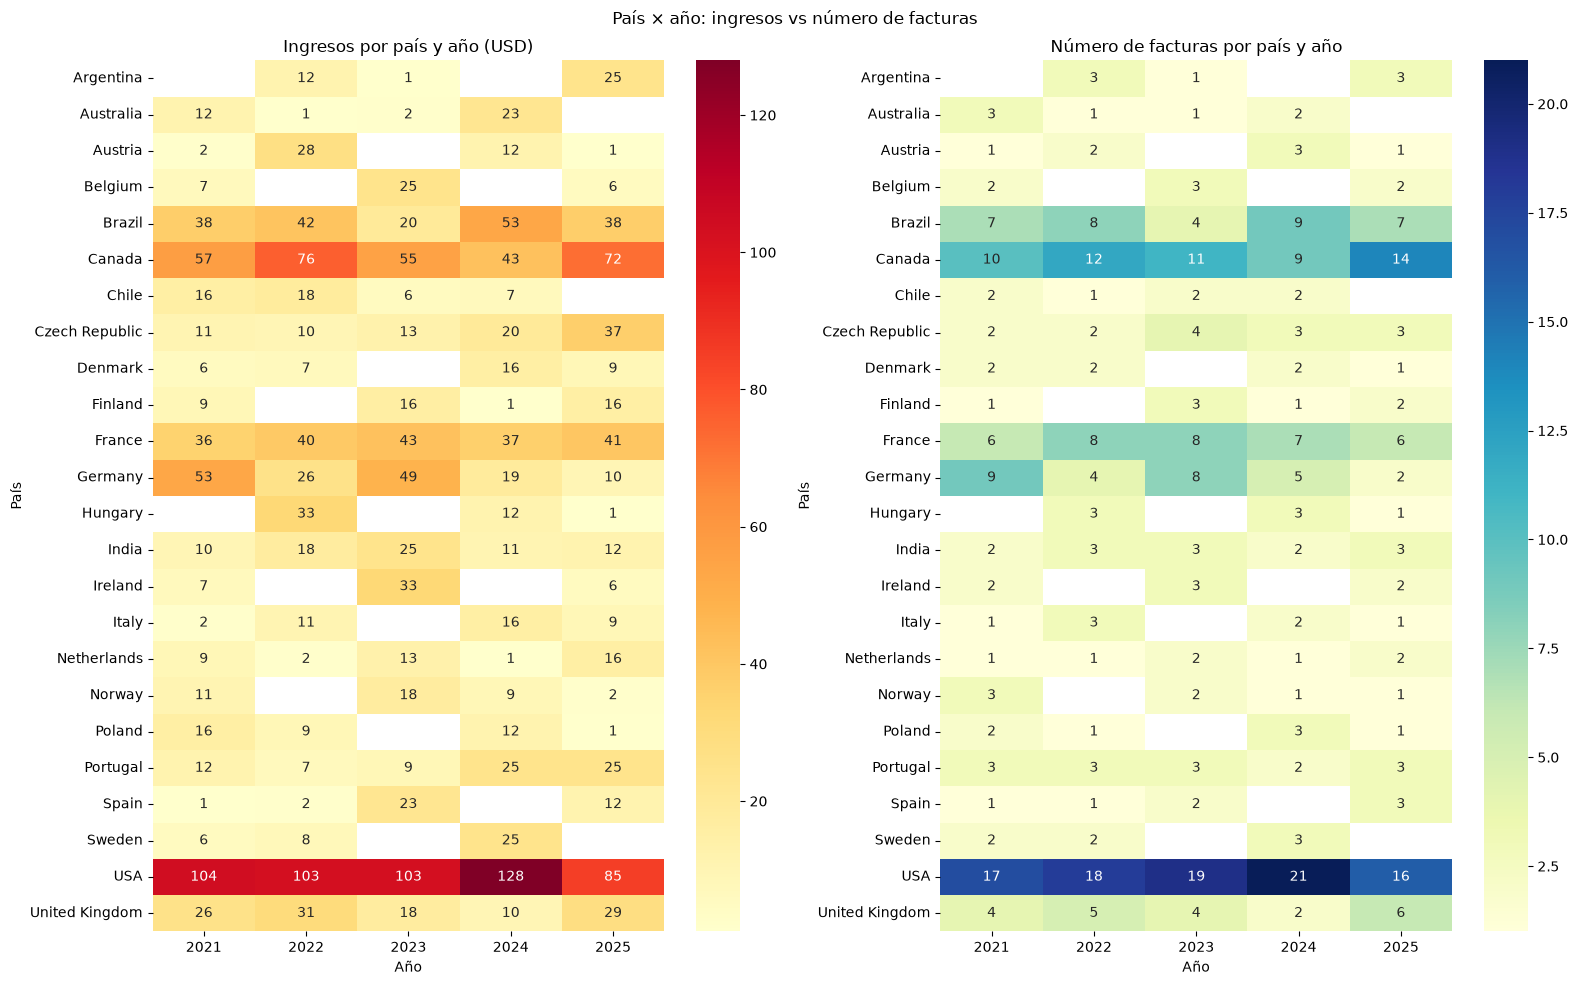

Facturas por cliente (valores distintos): [7 6]


In [ ]:


# Tabla de ingresos
tabla_ingresos_pais_año = facturas_con_fecha.pivot_table(
    index="BillingCountry", columns="Año", values="Total", aggfunc="sum"
)

# Tabla nueva: número de facturas por país y año
tabla_facturas_pais_año = facturas_con_fecha.pivot_table(
    index="BillingCountry", columns="Año", values="Total", aggfunc="count"
)

figura, ejes = plt.subplots(1, 2, figsize=(16, 10))

sns.heatmap(tabla_ingresos_pais_año, annot=True, fmt=".0f", cmap="YlOrRd", ax=ejes[0])
ejes[0].set_title("Ingresos por país y año (USD)")
ejes[0].set_xlabel("Año")
ejes[0].set_ylabel("País")

sns.heatmap(tabla_facturas_pais_año, annot=True, fmt=".0f", cmap="YlGnBu", ax=ejes[1])
ejes[1].set_title("Número de facturas por país y año")
ejes[1].set_xlabel("Año")
ejes[1].set_ylabel("País")

figura.suptitle("País × año: ingresos vs número de facturas")
plt.tight_layout()
plt.show()


facturas_por_cliente = invoice.groupby("CustomerId")["InvoiceId"].count()
print("Facturas por cliente (valores distintos):", facturas_por_cliente.unique())

#### ¿Cambia la historia?
**La historia general no cambia:** Estados Unidos y Canadá siguen arriba en los dos heatmaps, seguidos de Brasil, Francia y Alemania

**Los detalles sí cambian:**
- En el número de facturas casi todo se ve muy parejo, porque en Chinook cada cliente tiene 6 o 7 facturas en total. Lo que se ve en ese heatmap es básicamente cuántos clientes tiene cada país
- En el heatmap de ingresos aparecen picos que no se ven en el de facturas. Por ejemplo, Argentina en 2025 (3 facturas = 25 USD), Hungría en 2022 (3 facturas = 33 USD) e Irlanda en 2023 (3 facturas = 33 USD)
- Conclusión: los ingresos dependen sobre todo del **tamaño de cada compra**, no de qué tan seguido compra el cliente